# 06 · Voz: ASR, TTS con clonación, escenarios hablados y latencias

**Laboratorio 4 · Asistente de compras por voz** (MCD8016 Deep Learning, UTEC)

Este notebook cubre los requisitos de voz del enunciado:

| Requisito | Dónde |
|---|---|
| ASR en español integrado a la conversación | §2 y §3 (Whisper large-v3-turbo) |
| Respuestas con **voz propia** a partir de una grabación de referencia; textos generados **distintos** del de la referencia | §1 y §5 (XTTS-v2) |
| 6 escenarios por audio (≥ 3 con varias intervenciones), conservando audios, transcripciones, operaciones y estado final | §3 |
| **Repetir los casos de voz con la transcripción correcta** para identificar errores del ASR | §4 |
| Errores de transcripción en **cantidades, importes y productos** | §4 |
| **Inteligibilidad** y **semejanza** con la voz de referencia | §5 |
| Tiempo desde el fin de la grabación hasta que la respuesta puede reproducirse, **por etapa**, separando la **carga inicial** | §6 |

### Modelos (todo local, sin APIs externas)
| Etapa | Mac (desarrollo) | Colab (oficial) | Por qué |
|---|---|---|---|
| ASR | `mlx-whisper` large-v3-turbo | `faster-whisper` large-v3-turbo (GPU, fp16) | Mejor relación calidad/velocidad de Whisper en español; ~1,6 GB |
| TTS | XTTS-v2 en CPU (en MPS es 2× más lento) | XTTS-v2 en GPU | Clona una voz con ~20 s de referencia y habla español de forma nativa. Licencia CPML (no comercial) |
| Semejanza | ECAPA-TDNN (SpeechBrain) | igual | Embeddings de hablante estándar (VoxCeleb) |

### Grabaciones
- **Referencia:** `data/voz/referencia.wav`, ~24 s de **la voz del autor**, leyendo un texto que el asistente nunca dice. Se graba con `uv run lab4-conversar --nueva-referencia`.
- **Turnos de los 6 escenarios:** `data/voz/escenarios/V1…V6/turno_NN.wav`, grabados con `uv run lab4-grabar`. En V5 el turno 1 dice «cincuenta» a propósito, para simular el error de transcripción que luego se corrige.
- En Colab, se sube la carpeta `data/voz/` a `MyDrive/lab4/data/voz/`.

## 0. Entorno y carga inicial de modelos

In [ ]:
# ── Configuración del entorno (idéntica en todos los notebooks) ──────────────────────────
# Detectar si corre en Colab o en la Mac y dejar importable el paquete `asistente_compras`.
import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    # 1) Montar Drive: guarda el código y los datos entre sesiones (Colab borra /content al cerrar).
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/lab4/lab4_solution")
    os.environ["LAB4_DATA_DIR"] = "/content/drive/MyDrive/lab4/data"
    # 2) Instalar el paquete y sus dependencias. EXTRAS cambia según el notebook
    #    ("" = núcleo; "rag", "llm", "voz" en los siguientes).
    EXTRAS = "rag,llm,voz"
    target = f"{PROJECT_DIR}[{EXTRAS}]" if EXTRAS else str(PROJECT_DIR)
    get_ipython().run_line_magic("pip", f"install -q -e {target}")
else:
    # En la Mac, usar como kernel el entorno uv del proyecto (ver README).
    PROJECT_DIR = Path.cwd().resolve().parent

# Una instalación editable recién hecha no se ve hasta reiniciar el kernel;
# agregar src/ al path para evitar ese reinicio.
sys.path.insert(0, str(PROJECT_DIR / "src"))
print(f"Colab: {EN_COLAB} | proyecto: {PROJECT_DIR}")

In [2]:
import json

import pandas as pd
from IPython.display import Audio, display

from asistente_compras.cli import REFERENCE_TEXT
from asistente_compras.config import get_paths
from asistente_compras.evaluation import timed
from asistente_compras.llm import make_llm
from asistente_compras.retrieval import build_system_retriever
from asistente_compras.scenarios import SCENARIOS, evaluate, run_scenario, save_run
from asistente_compras.voice import SpeakerSimilarity, XTTSVoice, make_asr, wer

MODELO = "qwen3.5:9b"  # el elegido en el notebook 05

paths = get_paths().ensure()
VOZ = paths.root / "voz"
REF = VOZ / "referencia.wav"
OUT = paths.root / ("voz_resultados_colab" if EN_COLAB else "voz_resultados")
catalog = pd.read_parquet(paths.processed / "catalog.parquet")

# Medir la carga inicial (una sola vez): se reporta aparte de las consultas posteriores.
carga = {}
retriever, carga["recuperador (BM25 + e5 + re-ranker)"] = timed(build_system_retriever, catalog, paths.index)
llm, carga["LLM"] = timed(make_llm, MODELO)
asr, carga["ASR (Whisper)"] = timed(make_asr)
tts, carga["TTS (XTTS-v2 + latentes de la referencia)"] = timed(XTTSVoice, REF)
sim, carga["semejanza (ECAPA)"] = timed(SpeakerSimilarity)
# Medir la primera inferencia de cada modelo (calentamiento), también parte del costo inicial.
_, carga["calentamiento LLM"] = timed(llm.chat, [{"role": "user", "content": "hola"}], [])
_, carga["calentamiento ASR"] = timed(asr.transcribe, REF)
pd.Series(carga, name="segundos").round(1).to_frame()

,segundos
recuperador (BM25 + e5 + re-ranker),75.2
LLM,67.9
ASR (Whisper),12.1
TTS (XTTS-v2 + latentes de la referencia),32.5
semejanza (ECAPA),5.7
calentamiento LLM,47.1
calentamiento ASR,1.4


## 1. Voz de referencia

Es la grabación del autor que se clona. El texto leído (abajo) no coincide con ninguna respuesta del asistente: el enunciado exige que *"los textos generados deberán ser distintos de los de la referencia"*.

In [3]:
import soundfile as sf

print(f"Duración: {sf.info(str(REF)).duration:.1f} s\nTexto leído: «{REFERENCE_TEXT}»")
display(Audio(str(REF)))

Duración: 23.6 s


## 2. Grabaciones de los 6 escenarios de voz

In [4]:
VOICE = [s for s in SCENARIOS if s.voice]
audios = {s.id: [VOZ / "escenarios" / s.id / f"turno_{i:02d}.wav" for i in range(1, len(s.turns) + 1)]
          for s in VOICE}
faltan = [str(p) for ps in audios.values() for p in ps if not p.exists()]
assert not faltan, f"Faltan {len(faltan)} grabaciones (uv run lab4-grabar): {faltan[:3]}…"
pd.DataFrame([{"id": s.id, "escenario": s.title, "turnos": len(s.turns),
               "segundos de audio": round(sum(sf.info(str(p)).duration for p in audios[s.id]), 1)}
              for s in VOICE]).set_index("id")

,escenario,turnos,segundos de audio
id,,,
V1,Compra que cumple las restricciones,3,12.2
V2,Solicitud ambigua que requiere aclaración,4,10.3
V3,Cambio de cantidad conservando el presupuesto,4,12.1
V4,Producto agotado: buscar alternativa,4,9.9
V5,Corrección de la transcripción antes de comprar,4,12.5
V6,Cambio de stock entre cotización y confirmació...,6,17.3


## 3. Escenarios por voz: ASR → agente → TTS

Cada escenario parte de su estado inicial reproducible. En cada turno, el audio grabado se transcribe con Whisper, la transcripción (con sus errores) va al agente y la respuesta se sintetiza con la voz clonada. Se guardan los audios de respuesta, las transcripciones, las operaciones y el estado final.

In [5]:
voz_runs = {}
for s in VOICE:
    run = run_scenario(s, llm, retriever, catalog, paths.root / "store" / "voz.db",
                       audio=audios[s.id], asr=asr, tts=tts, audio_out_dir=OUT / "audio")
    save_run(run, OUT / "trazas", tag="_voz")
    voz_runs[s.id] = run
    ev = evaluate(run)
    print(f"{'✅' if ev['passed'] else '❌'} {s.id} {s.title}: verificaciones {ev['checks_ok']}/"
          f"{ev['checks_total']}, violaciones {ev['violations']}")
    for f in ev["failed_checks"]:
        print(f"     ↳ {f}")

✅ V1 Compra que cumple las restricciones: verificaciones 4/4, violaciones 0
✅ V2 Solicitud ambigua que requiere aclaración: verificaciones 4/4, violaciones 0
❌ V3 Cambio de cantidad conservando el presupuesto: verificaciones 3/4, violaciones 0
     ↳ pedido contiene ('botella',): faltan ['botella']
❌ V4 Producto agotado: buscar alternativa: verificaciones 1/4, violaciones 0
     ↳ busca alternativas tras «out_of_stock»: herramientas tras el error: ['actualizar_carrito', 'consultar_precio_stock', 'actualizar_carrito', 'consultar_precio_stock']
     ↳ pedidos == 1: pedidos=0
     ↳ pedido contiene ('rat[oó]n|mouse',): faltan ['rat[oó]n|mouse']
✅ V5 Corrección de la transcripción antes de comprar: verificaciones 3/3, violaciones 0
❌ V6 Cambio de stock entre cotización y confirmación; confirmación repetida: verificaciones 4/5, violaciones 0
     ↳ se detectó «stock_changed»: errores=[]


In [ ]:
# Mostrar la conversación completa de un escenario con varias intervenciones: audio del usuario, lo que
# entendió el ASR, la respuesta y su audio con la voz clonada.
EJEMPLO = "V6"
for v in voz_runs[EJEMPLO].voice:
    print(f"── Turno {v['turn']}\n👤 dijo:     «{v['gold']}»\n🎙 entendió: «{v['transcript']}»"
          f"  (WER {v['wer']:.2f})\n🤖 «{v['response']}»")
    display(Audio(v["audio_in"]), Audio(v["audio_out"]))

## 4. Errores del ASR: los mismos escenarios con la transcripción correcta

Se repite cada escenario dándole al agente el **texto correcto** en lugar del ASR (sin TTS, porque no influye en la lógica). Si un escenario falla con voz y pasa con texto, el fallo se debe al ASR.

In [7]:
texto_runs = {s.id: run_scenario(s, llm, retriever, catalog, paths.root / "store" / "voz.db")
              for s in VOICE}
comp = pd.DataFrame([{
    "id": s.id, "escenario": s.title,
    "con voz (ASR)": "✅" if evaluate(voz_runs[s.id])["passed"] else "❌",
    "con transcripción correcta": "✅" if evaluate(texto_runs[s.id])["passed"] else "❌",
} for s in VOICE]).set_index("id")
comp["diagnóstico"] = [
    "fallo atribuible al ASR" if a == "❌" and b == "✅" else
    "fallo del agente (no del ASR)" if b == "❌" else "ok"
    for a, b in zip(comp["con voz (ASR)"], comp["con transcripción correcta"])]
comp

,escenario,con voz (ASR),con transcripción correcta,diagnóstico
id,,,,
V1,Compra que cumple las restricciones,✅,✅,ok
V2,Solicitud ambigua que requiere aclaración,✅,✅,ok
V3,Cambio de cantidad conservando el presupuesto,❌,❌,fallo del agente (no del ASR)
V4,Producto agotado: buscar alternativa,❌,❌,fallo del agente (no del ASR)
V5,Corrección de la transcripción antes de comprar,✅,✅,ok
V6,Cambio de stock entre cotización y confirmació...,❌,❌,fallo del agente (no del ASR)


In [8]:
# Medir los errores de transcripción por turno (cantidades, importes y productos, como pide el enunciado).
asr_df = pd.DataFrame([{"id": sid, **{k: v[k] for k in ("turn", "gold", "transcript", "wer",
                        "err_cantidades", "err_importes", "err_productos")}}
                       for sid, r in voz_runs.items() for v in r.voice])
print(f"Turnos: {len(asr_df)} · WER medio {asr_df.wer.mean():.3f} · "
      f"turnos con WER > 0: {(asr_df.wer > 0).sum()}")
print("Errores totales →",
      {k: int(asr_df[k].sum()) for k in ("err_cantidades", "err_importes", "err_productos")})
asr_df[asr_df.wer > 0]

Turnos: 25 · WER medio 0.000 · turnos con WER > 0: 0
Errores totales → {'err_cantidades': 0, 'err_importes': 0, 'err_productos': 0}


,id,turn,gold,transcript,wer,err_cantidades,err_importes,err_productos


## 5. Calidad de la voz sintetizada

- **Inteligibilidad:** se transcribe cada respuesta sintetizada con Whisper y se compara con el texto que se quiso decir (WER normalizado: los números se comparan en palabras). Cuanto más bajo, mejor.
- **Semejanza:** similitud coseno ECAPA entre la referencia y cada respuesta. Como referencia de escala, se compara también **otra grabación real del autor** (techo práctico) y una **voz distinta** (piso).

In [9]:
filas = []
for sid, r in voz_runs.items():
    for v in r.voice:
        filas.append({"id": sid, "turno": v["turn"],
                      "wer_tts": wer(v["spoken_text"], asr.transcribe(v["audio_out"]).text),
                      "semejanza": sim.similarity(REF, v["audio_out"])})
tts_df = pd.DataFrame(filas)
techo = sim.similarity(REF, audios["V1"][0])        # otra grabación real del autor
print(f"Inteligibilidad: WER medio {tts_df.wer_tts.mean():.3f} "
      f"(mediana {tts_df.wer_tts.median():.3f}) sobre {len(tts_df)} respuestas")
print(f"Semejanza con la referencia: media {tts_df.semejanza.mean():.3f} "
      f"(mín {tts_df.semejanza.min():.3f}) · otra grabación real del autor: {techo:.3f}")
tts_df.groupby("id")[["wer_tts", "semejanza"]].mean().round(3)

Inteligibilidad: WER medio 0.052 (mediana 0.029) sobre 25 respuestas
Semejanza con la referencia: media 0.816 (mín 0.771) · otra grabación real del autor: 0.715


,wer_tts,semejanza
id,,
V1,0.017,0.824
V2,0.013,0.824
V3,0.190,0.813
V4,0.052,0.818
V5,0.041,0.833
V6,0.013,0.796


## 6. Latencia por etapa

Se mide **desde que termina la grabación** hasta que el audio de respuesta está listo para reproducirse. La carga inicial de los modelos (§0) no se incluye: se reporta aparte.

In [10]:
lat = pd.DataFrame([v for r in voz_runs.values() for v in r.voice])
etapas = {"asr_s": "ASR", "llm_s": "LLM", "tools_s": "herramientas + recuperación",
          "tts_s": "TTS", "total_s": "TOTAL"}
tabla_lat = lat[list(etapas)].rename(columns=etapas).describe(percentiles=[0.5, 0.9]) \
    .loc[["mean", "50%", "90%", "max"]].T.round(2)
tabla_lat.columns = ["media", "mediana", "p90", "máx"]
tabla_lat

,media,mediana,p90,máx
ASR,0.26,0.21,0.23,1.48
LLM,10.94,11.41,15.05,18.90
herramientas + recuperación,0.12,0.05,0.38,0.39
TTS,10.01,10.53,16.84,18.26
TOTAL,21.34,20.76,29.16,33.53


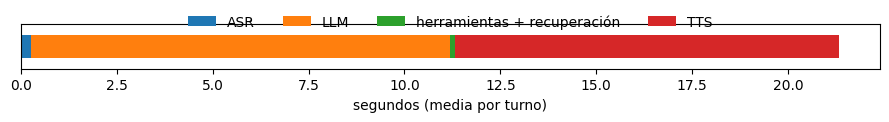

In [11]:
import matplotlib.pyplot as plt

partes = lat[["asr_s", "llm_s", "tools_s", "tts_s"]].mean().rename(etapas)
ax = partes.to_frame().T.plot.barh(stacked=True, figsize=(9, 1.8), legend=True)
ax.set_xlabel("segundos (media por turno)"); ax.set_yticks([])
ax.legend(ncol=4, bbox_to_anchor=(0.5, 1.5), loc="upper center", frameon=False)
plt.tight_layout(); plt.show()

In [ ]:
# Guardar todas las métricas para el informe.
asr_df.to_csv(OUT / "asr_por_turno.csv", index=False)
tts_df.to_csv(OUT / "tts_calidad.csv", index=False)
lat.drop(columns=["response", "spoken_text"], errors="ignore").to_csv(OUT / "latencias.csv", index=False)
pd.Series(carga).to_csv(OUT / "carga_inicial.csv")
comp.to_csv(OUT / "voz_vs_texto.csv")
print("Resultados en", OUT)

### Resumen
- La sección 3 muestra el porcentaje de escenarios de voz correctos; la sección 4 separa qué fallos se deben al ASR y cuáles al agente.
- Las secciones 5 y 6 dan la inteligibilidad, la semejanza de voz y las latencias por etapa, con la carga inicial aparte.
- Estos números son los de la Mac; los oficiales salen de ejecutar este notebook en Colab con GPU.